# **K-means: Studi Kasus Segmentasi Pelanggan Mall**

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
df = pd.read_csv('Mall_Customers.csv')
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


## **1. Data Preprocessing**

Dataset ini terdiri atas 5 kolom, dimana kolom pertama berupa CustomerID sebagai penanda pelanggan, Gender yaitu jenis kelamin pelanggan, Age yaitu umur pelanggan, Annual Income (k$) yaitu pendapatan pertahun, dan Spending Score (1–100) yaitu nilai yang diberikan oleh mall kepada pelanggan sebagai penilaian seberapa besar seseorang
mengeluarkan uang di mall.

In [ ]:
#Missing values
print("missing value :")
print(df.isna().sum())
#Cek Duplikasi Data
print("jumlah duplikasi = ", df.duplicated().sum())

missing value :
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
jumlah duplikasi =  0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


Customer ID berisi ID perlanggan dan tidak ada relasi dengan kelompok pelanggan. Oleh karena itu kita tidak membutuhkan kolom CustomerID.

----------------------------------------

Selanjutnya, pada kolom Gender terdapat dua nilai yakni Male dan Female, maka kita akan menggunakan LabelEncoder untuk merubah Female menjadi value 0 dan Male menjadi value 1.

----------------------------------------

**LabelEncoder** sendiri bekerja dengan
cara merubah seluruh kategori yang ada di dalam suatu kolom menjadi angka. Angka tersebut diurutkan berdasarkan huruf abjad dari kategori yang ada.

In [ ]:
#menghapus feature CustomerID
df.drop('CustomerID', axis = 1, inplace = True)
#rename kolom
df.rename(columns = {'Annual Income (k$)': 'Annual Income'}, inplace = True)
df.rename(columns = {'Spending Score (1-100)': 'Spending Score'}, inplace = True)

#merubah nilai male dan female menjadi numeric
from sklearn.preprocessing import StandardScaler, LabelEncoder
labeler = LabelEncoder()
df['Gender'] = labeler.fit_transform(df['Gender'])
df

,Gender,Age,Annual Income,Spending Score
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40
...,...,...,...,...
195,0,35,120,79
196,0,45,126,28
197,1,32,126,74
198,1,32,137,18


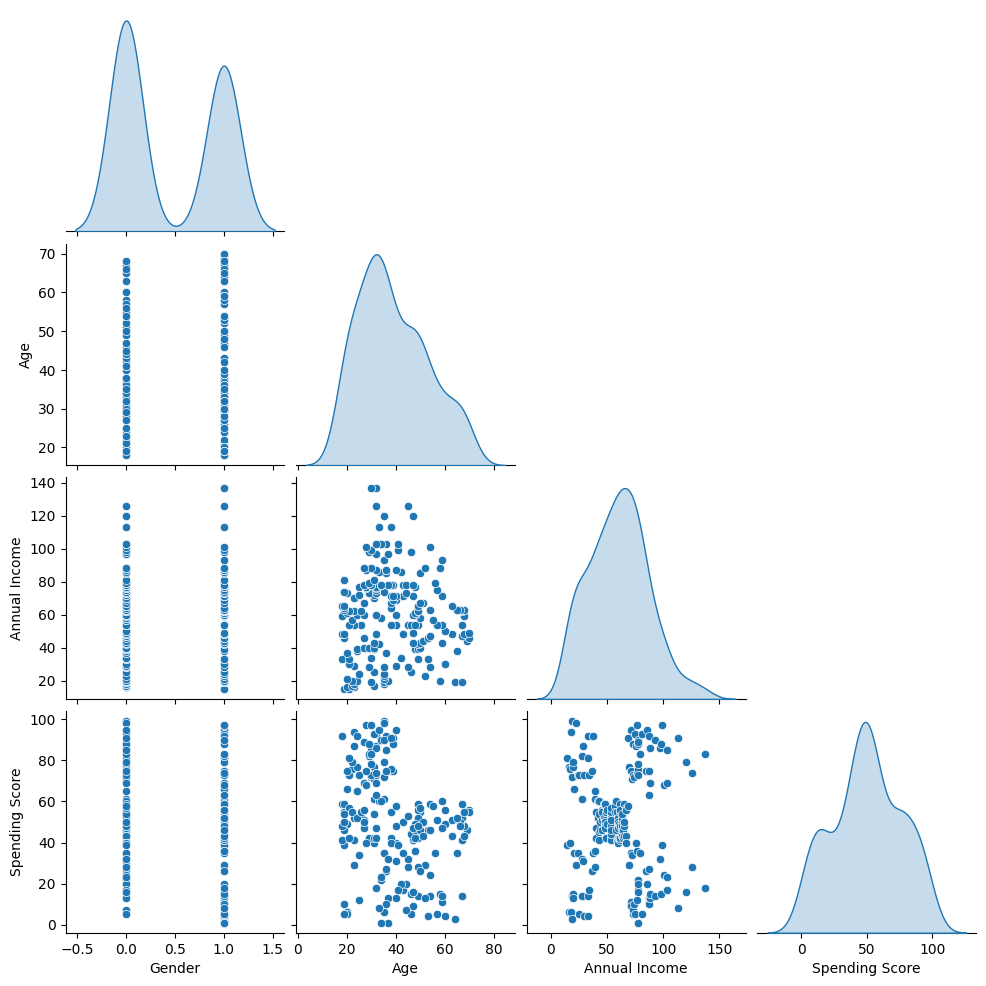

In [ ]:
sns.pairplot(df,corner=True,diag_kind="kde")
plt.show()

Hal menarik yang dapat kita lihat dari data dan visualisasi data di atas adalah:

*   Pengunjung Mall lebih banyak perempuan/female berjumlah 112 sedangkan laki-laki berjumlah

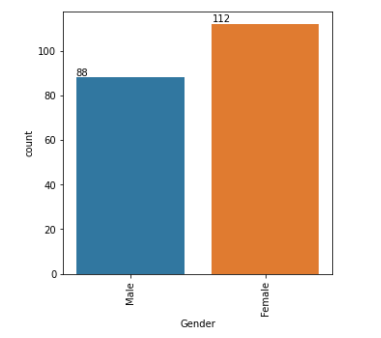

*   Rentang umur pengunjung dari 18 sampai 70 tahun, namun sebagian besar pelanggan Mall dengan rentang umur yang lebih muda
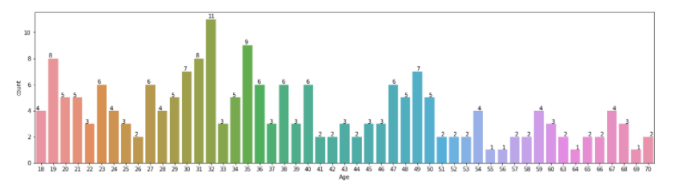


*   Sebagian besar pelanggan mall memiliki pendapatan dibawah 100K$
*   Terdapat Normal distribusi untuk Spending Score pelanggan, yaitu mendekati nilai 50





In [ ]:
df.describe()

,Gender,Age,Annual Income,Spending Score
count,200.000000,200.000000,200.000000,200.000000
mean,0.440000,38.850000,60.560000,50.200000
std,0.497633,13.969007,26.264721,25.823522
min,0.000000,18.000000,15.000000,1.000000
25%,0.000000,28.750000,41.500000,34.750000
50%,0.000000,36.000000,61.500000,50.000000
75%,1.000000,49.000000,78.000000,73.000000
max,1.000000,70.000000,137.000000,99.000000


Karena jarak data beragam, maka kita akan melakukan **normalisasi** terhadap data **menggunakan Z-score** sehingga data memiliki mean 0 dan standard deviation 1. Semua kolom akan dinormalisasi kecuali Gender.

In [ ]:
#Scaling Data
scaler = StandardScaler()
# scaling kecuali gender
Gender = df['Gender']
df.drop('Gender', axis = 1)
#proses scaling
df = pd.DataFrame(scaler.fit_transform(df), columns = df.columns)
df['Gender'] = Gender
df.head(5)

,Gender,Age,Annual Income,Spending Score
0,1,-1.424569,-1.738999,-0.434801
1,1,-1.281035,-1.738999,1.195704
2,0,-1.352802,-1.700830,-1.715913
3,0,-1.137502,-1.700830,1.040418
4,0,-0.563369,-1.662660,-0.395980


## **2. Training Model**

Sebelum memulai pelatihan berarti kita harus menentukan jumlah kluster. Namun, pada kasus ini kita tidak mengetahuinya oleh karena itu kita dapat menggunakan **elbow method**.

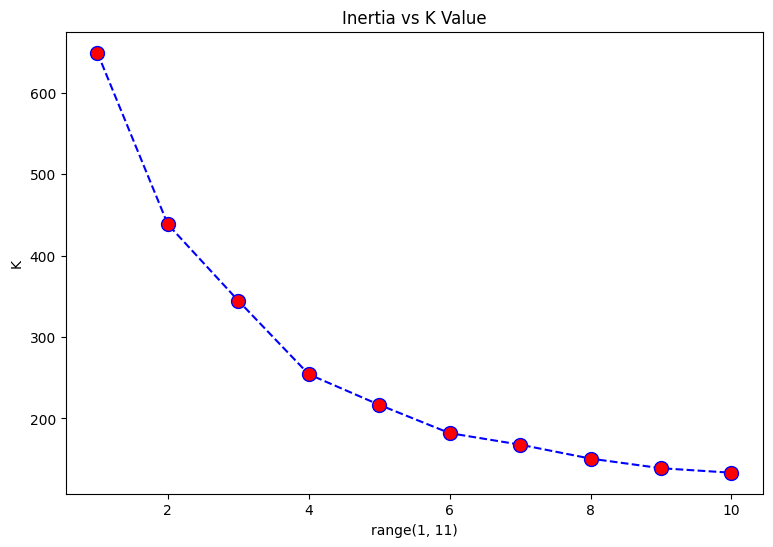

In [ ]:
from sklearn.cluster import KMeans
inertia_list = []
for i in range(1,11):
    kmeans = KMeans(n_clusters=i, random_state= 42, n_init=10)
    kmeans.fit(df)
    inertia_list.append(kmeans.inertia_)

plt.figure(figsize = (9,6))
plt.plot(range(1,11), inertia_list, color = 'blue',
          linestyle = 'dashed', marker = 'o',
          markerfacecolor = 'red', markersize = 10)
plt.title('Inertia vs K Value')
plt.xlabel(range(1,11,1))
plt.ylabel('K')
plt.show('Inertia')

Female:  112
Male:  88


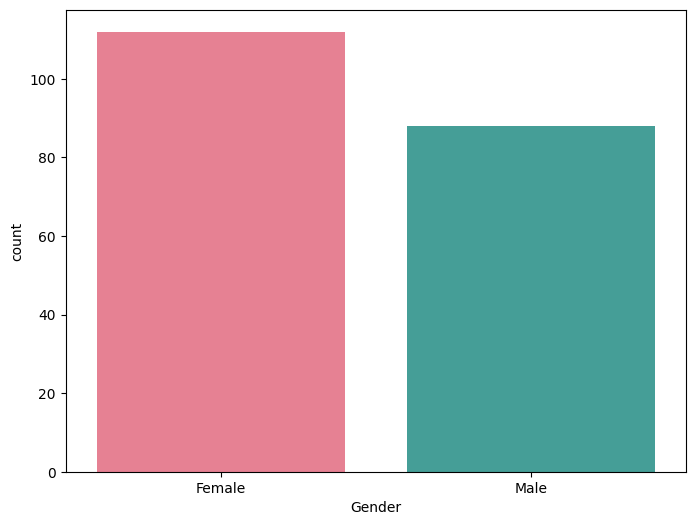

In [ ]:
from matplotlib.pyplot import figure, show
import seaborn as sns

plt.figure(figsize=(8,6))
ax = sns.countplot(x=df['Gender'], hue="Gender", data=df, palette="husl", legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Female", "Male"])

female, male = df["Gender"].value_counts().values
print("Female: ", female)
print("Male: ", male)

plt.show()

Inertia adalah total jarak dari suatu centroid kepada data yang berada di kluster yang sama.

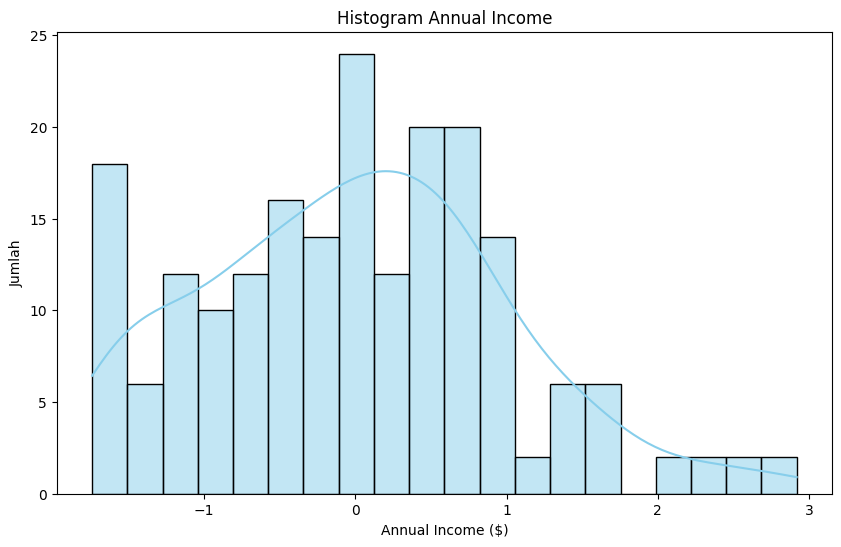

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
ax = sns.histplot(df["Annual Income"], bins=20, kde=True, color="skyblue")
ax.set_xlabel("Annual Income ($)")
ax.set_ylabel("Jumlah")
ax.set_title("Histogram Annual Income")

plt.show()

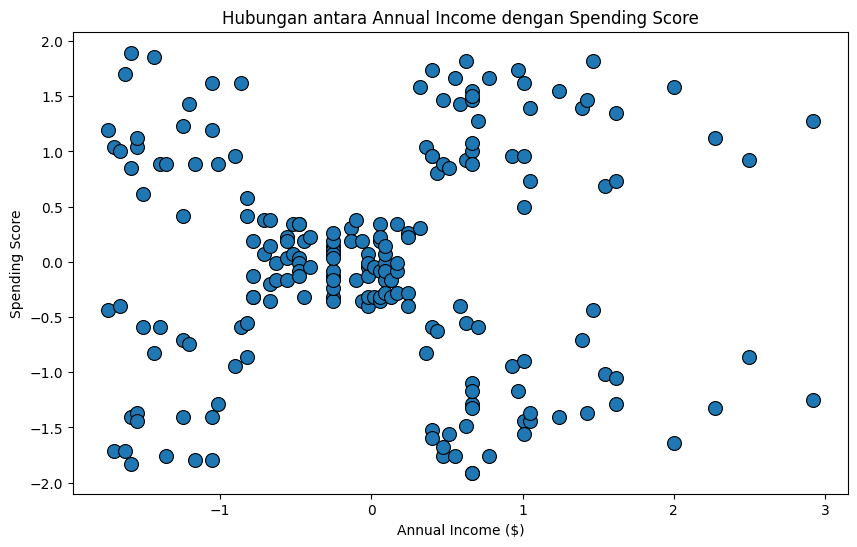

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.scatterplot(x=df["Annual Income"], y=df["Spending Score"], s=100, edgecolor="black")

plt.xlabel("Annual Income ($)")
plt.ylabel("Spending Score")
plt.title("Hubungan antara Annual Income dengan Spending Score")

plt.show()

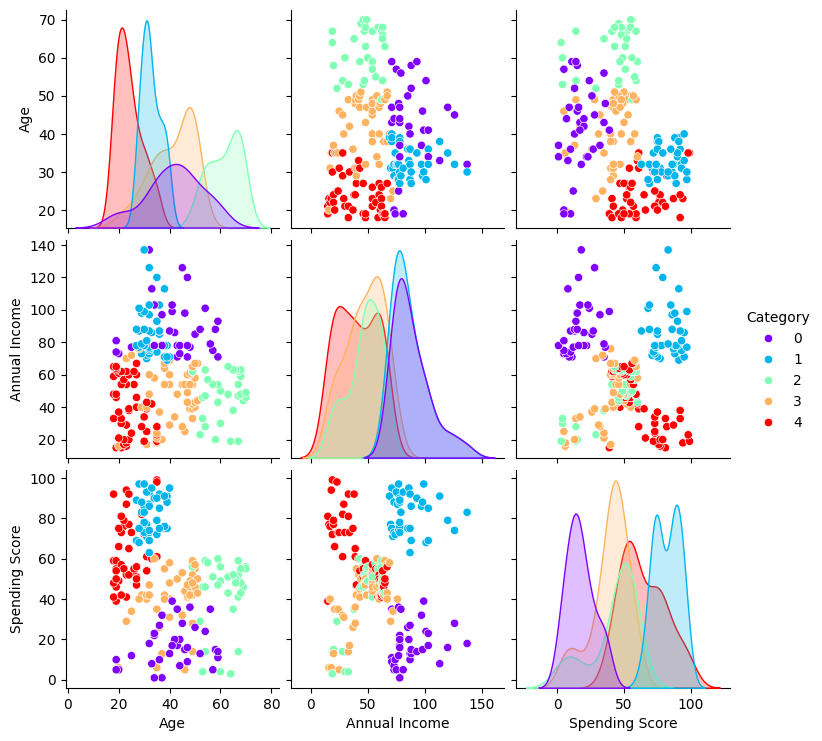

In [ ]:
km = KMeans(n_clusters=5).fit(df)
# Membaca kembali data asli ke variabel lain
# karena data untuk klustering telah diubah
df_ori = pd.read_csv("Mall_Customers.csv")
df_ori.drop('CustomerID', axis=1, inplace=True)
df_ori.rename(columns={'Annual Income (k$)': 'Annual Income', 'Spending Score (1-100)': 'Spending Score'}, inplace=True)

# Membuat satu kolom kategori untuk menampung hasil kluster kita
df_ori['Category'] = km.labels_
sns.pairplot(data=df_ori, hue='Category', palette='rainbow')

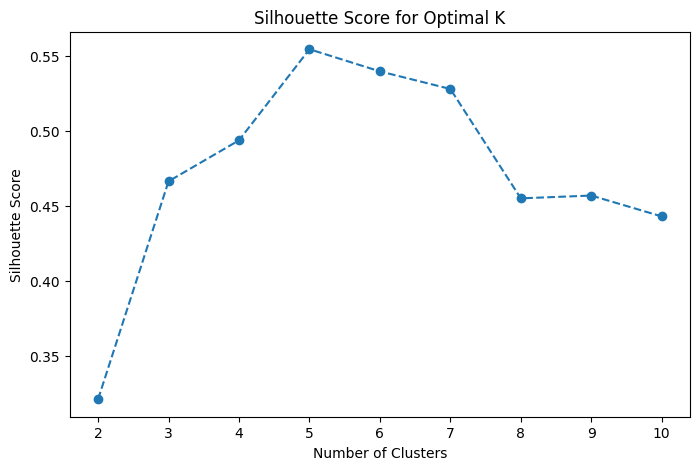

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df[['Annual Income', 'Spending Score']])
    silhouette_scores.append(silhouette_score(df[['Annual Income', 'Spending Score']], labels))

# Plot Silhouette Score
plt.figure(figsize=(8,5))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Optimal K")
plt.show()

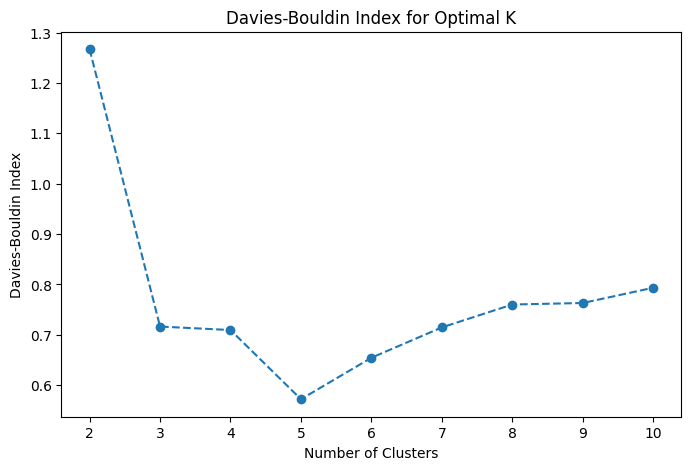

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score
import matplotlib.pyplot as plt

dbi_scores = []
K_range = range(2, 11)  # Minimal 2 Kluster

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df[['Annual Income', 'Spending Score']])
    dbi = davies_bouldin_score(df[['Annual Income', 'Spending Score']], labels)
    dbi_scores.append(dbi)

# Plot Davies-Bouldin Index
plt.figure(figsize=(8,5))
plt.plot(K_range, dbi_scores, marker='o', linestyle='--')
plt.xlabel("Number of Clusters")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index for Optimal K")
plt.show()

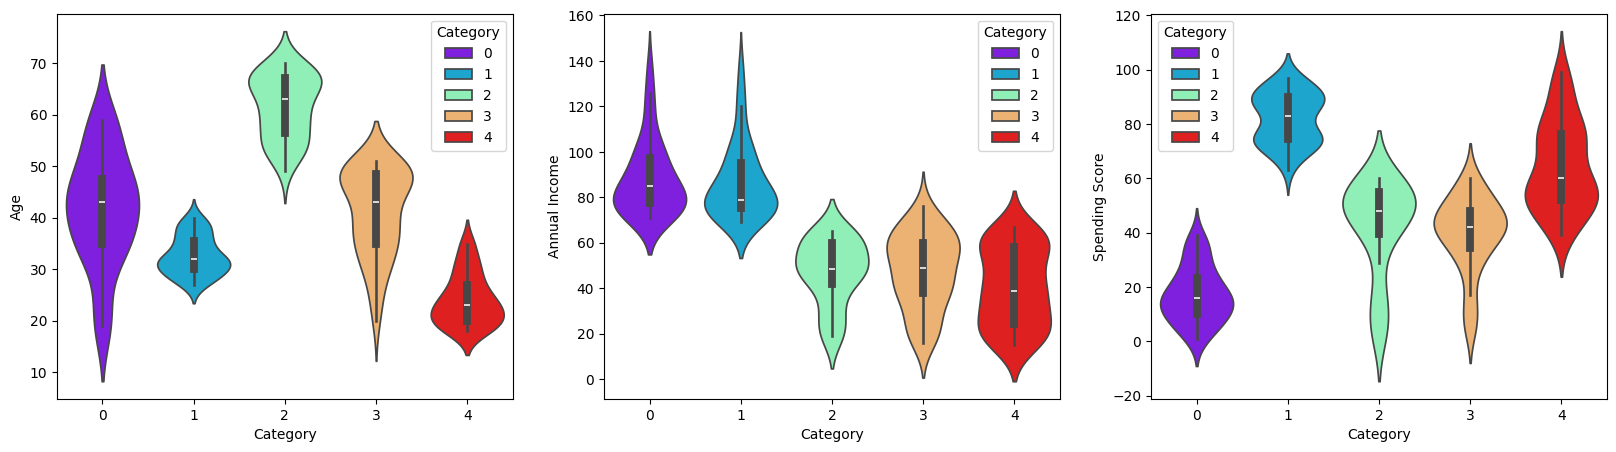

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.violinplot(x='Category', y='Age', data=df_ori, ax=axes[0], hue='Category', palette='rainbow')
sns.violinplot(x='Category', y='Annual Income', data=df_ori, ax=axes[1], hue='Category', palette='rainbow')
sns.violinplot(x='Category', y='Spending Score', data=df_ori, ax=axes[2], hue='Category', palette='rainbow')

plt.show()

In [ ]:
df_ori[['Age', 'Annual Income', 'Spending Score', 'Category']].groupby('Category').mean()

,Age,Annual Income,Spending Score
Category,,,
0,55.551724,48.482759,41.775862
1,25.272727,25.727273,79.363636
2,41.264706,88.500000,16.764706
3,27.957447,50.000000,44.638298
4,32.692308,86.538462,82.128205


Dengan melihat plot diatas, kita dapat memberikan kesimpulan dari pembagian data kita sebagai berikut:

*   **Kelompok 1 (Category=0)**
Memiliki rata-rata umur 37 tahun, dengan rata-rata annual income $91 K dan
spending score 40.

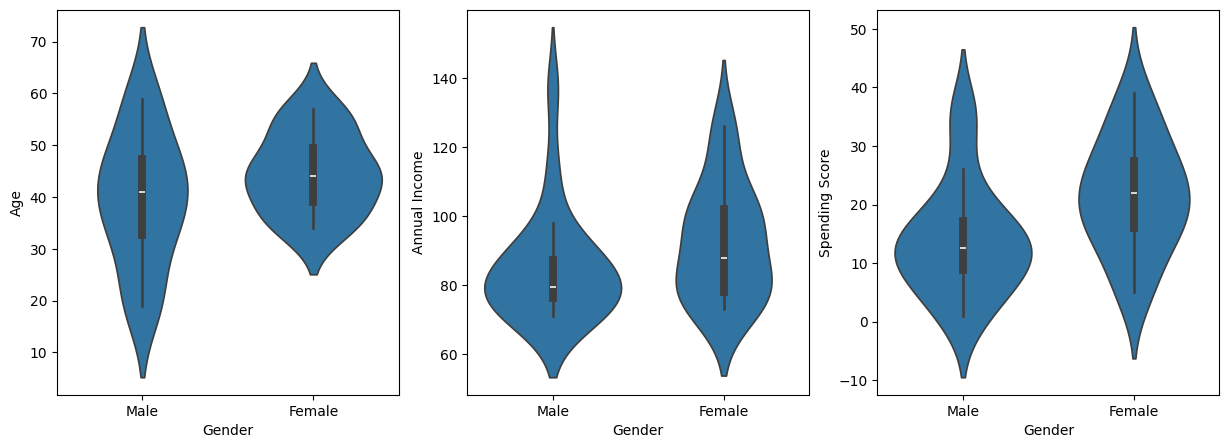

In [ ]:
group_1 = df_ori[df_ori['Category'] == 0]
group_1.head()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.violinplot(x='Gender', y='Age', data=group_1, ax=axes[0])
sns.violinplot(x='Gender', y='Annual Income', data = group_1, ax=axes[1])
sns.violinplot(x='Gender', y='Spending Score', data=group_1, ax=axes[2])
plt.show()

Dapat dikatakan kelompok ini dikatakan memiliki kelompok pria dan wanita paruh baya yang memiliki annual income yang tinggi dan spending yang rendah.


*   Kelompok 2 (Category=1)
Kelompok ini memiliki rata-rata umur 55 tahun dengan kelamin perempuan. Ratarata annual income dan spending score adalah $52K dan 36.


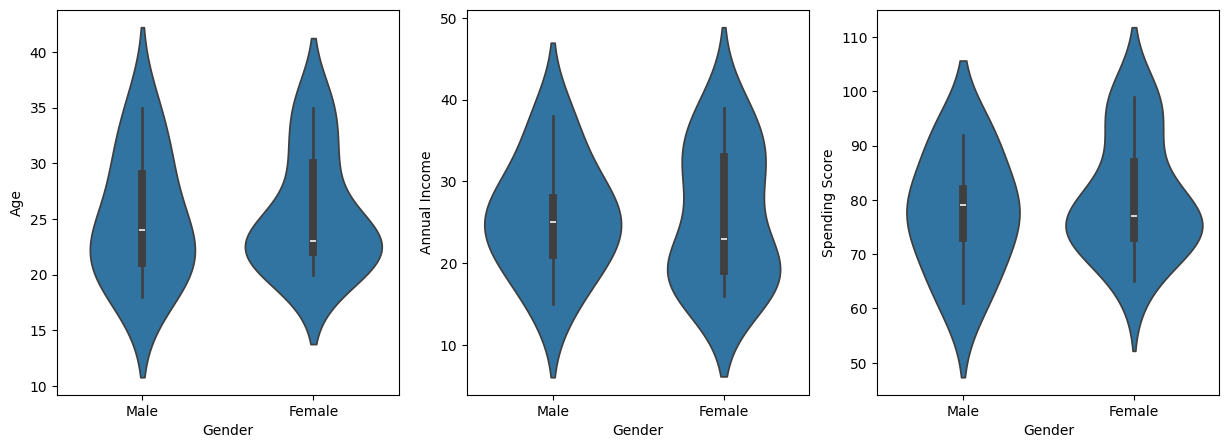

In [ ]:
group_2 = df_ori[df_ori['Category'] == 1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.violinplot(x='Gender', y='Age', data=group_2, ax=axes[0])
sns.violinplot(x='Gender', y='Annual Income', data=group_2, ax=axes[1])
sns.violinplot(x='Gender', y='Spending Score', data=group_2, ax=axes[2])
plt.show()

Kelompok ini adalah kelompok pria paruh baya yang memiliki pendapatan medium
dengan spending medium

*   Kelompok 3 (Category=2)



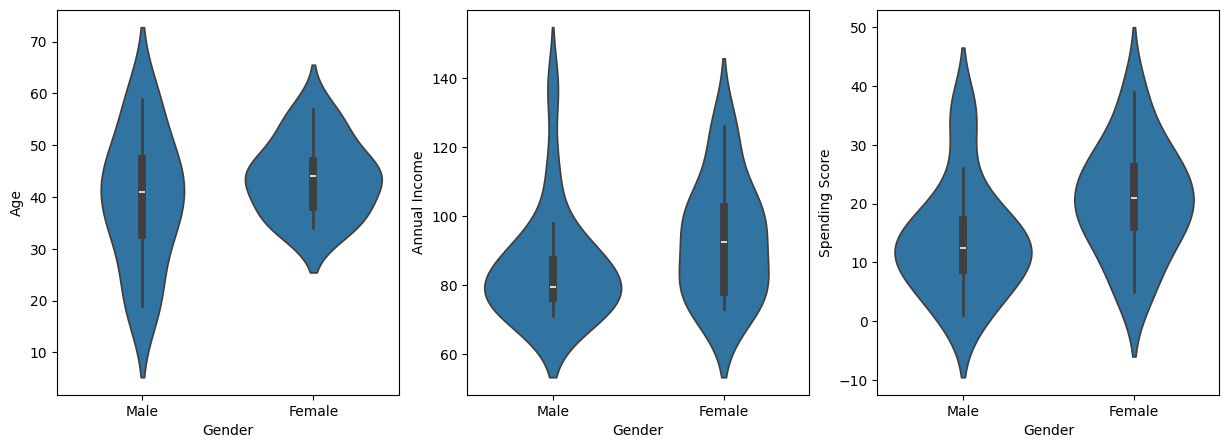

In [ ]:
group_3 = df_ori[df_ori['Category'] == 2]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.violinplot(x='Gender', y='Age', data=group_3, ax=axes[0])
sns.violinplot(x='Gender', y='Annual Income', data=group_3, ax=axes[1])
sns.violinplot(x='Gender', y='Spending Score', data=group_3, ax=axes[2])
plt.show()

Kelompok ini adalah kelompok wanita dengan pendapatan menengah ke bawah namun memiliki spending rendah.

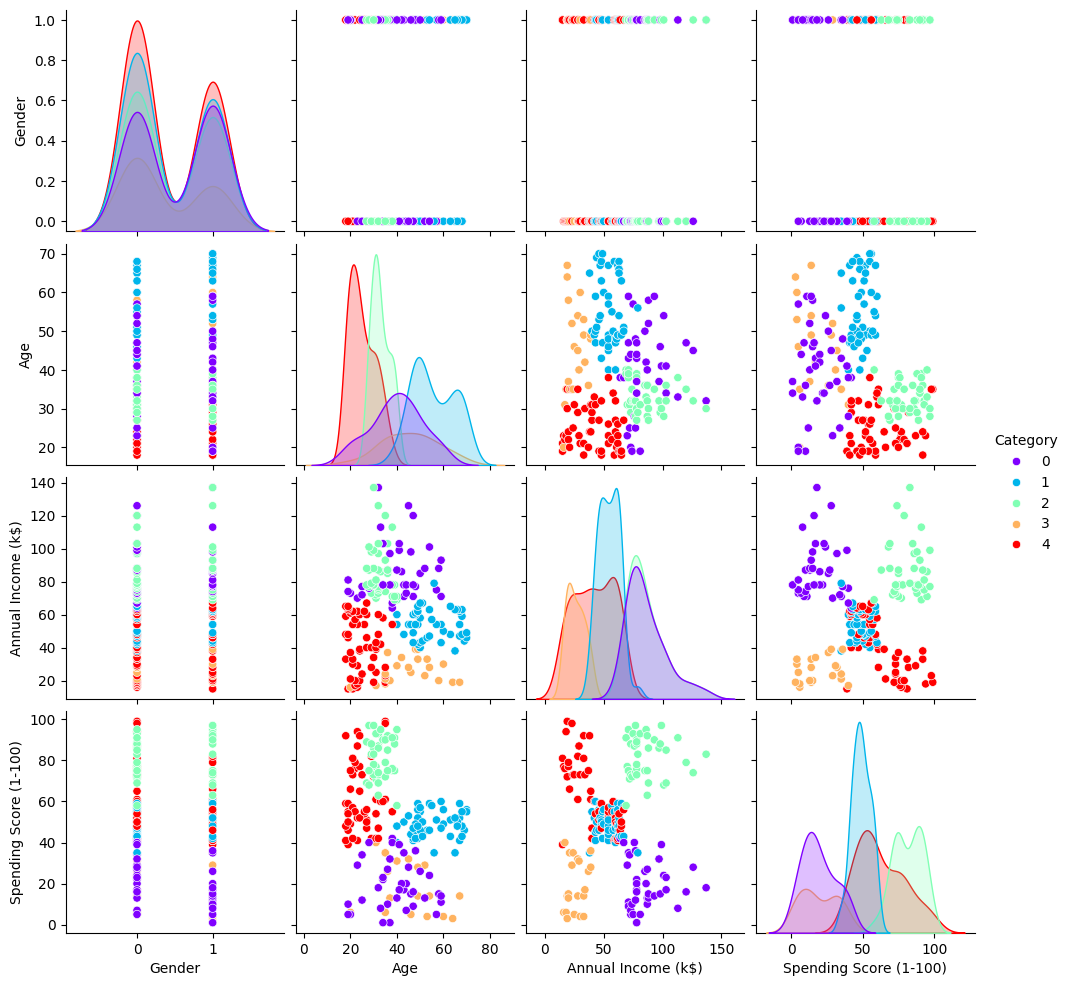

In [ ]:
df.drop('Gender', axis = 1)
km = KMeans(n_clusters=5).fit(df)
#Membaca kemballi original data ke variable lain
mall_ori = pd.read_csv('Mall_Customers.csv')
mall_ori.drop('CustomerID', axis = 1, inplace = True)ds
mall_ori['Gender'] = labeler.fit_transform(mall_ori['Gender'])
#Membuat stau kolom category untuk menampung hasil kluster kita
mall_ori['Category'] = km.labels_
sns.pairplot(data = mall_ori, hue = 'Category', palette = 'rainbow')

Sekarang, kita dapat mengambil kesimpulan dari hasil kluster di atas tanpa gender sebagai berikut:


*   Kelompok 0 merepresentasikan pelanggan dengan annual income sangat rendah, spending score rendah, dan rentang umur yang beragam
*   Kelompok 1 merepresentasikan pelanggan dengan annual income agak rendah, spending score agak rendah, dan memiliki rentang umur menengah hingga tua
*   Kelompok 2 merepresentasikan pelanggan dengan rentang umur menengah ke arah muda, annual income menengah hingga tinggi, serta spending score yang tinggi
*   Kelompok 3 merepresentasikan pelanggan dengan rentang umur muda, annual income yang rendah, serta spending score yang menengah hingga tinggi
*   Kelompok 4 merepresentasikan pelanggan dengan umur yang beragam, annual income menengah hingga tinggi, serta spending score yang rendah


Dengan merubah data yang dilatih, kita mampu mendapatkan perspektif baru. Selain
itu, dengan merubah nilai K juga, kita dapat melihat kelompok baru yang belum dapat
kita lihat





